<p style="align: center;"><img align=center src="https://drive.google.com/uc?export=view&id=1aS4vX-ucDKBmZmZMrBwgjl_DvLAadX2C" width=900/></p>


<h3 style="text-align: center;"><b>Школа глубокого обучения ФПМИ МФТИ</b></h3>

# Домашнее задание. RAG.

В этом домашнем задании вам предстоит создать туристический RAG, провести EDA и проявить креатив! :)

Вам дан набор данных, содержащий информацию о памятниках, архитектуре и других значимых местах. В данных есть:
* название достопримечательности;
* идентификатор на WikiData;
* город расположения;
* координаты долготы и широты;
* описание (извлеченное из WikiData);
* изображение в формате base64;
* сгенерированное описание изображения (генерация с помощью модели BLIP).

Некоторые из памятников могут встречаться несколько раз, но с различными изображениями, из которых не все могут быть качественными. Для компенсации этого даны текстовые описания.

Часть данных взята с Национальной технологической олимпиады студентов по CV. Базовое решение предполагает использование мультимодального ru-CLIP. Но в данном домашнем задании предлагается решить эту задачу творчески, используя NLP подход.

## Установка и импорт библиотек

In [1]:
# %pip install "langchain>=0.3,<0.4" "langchain-core>=0.3,<0.4" "langchain-community>=0.3,<0.4" "transformers==4.57.6" ragatouille chromadb

In [2]:
%pip install chromadb sentence-transformers pylate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.3/23.3 MB 118.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 63.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 530.7/530.7 MB 44.9 MB/s  0:00:07
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 366.1/366.1 MB 47.3 MB/s  0:00:06
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 169.9/169.9 MB 59.1 MB/s  0:00:02
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 196.5/196.5 MB 54.8 MB/s  0:00:03
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 188.3/188.3 MB 55.4 MB/s  0:00:03
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 423.1/423.1 MB 32.1 MB/s  0:00:09
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.7/40.7 MB 44.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.7/10.7 MB 53.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 70.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.5/7.5 MB 74.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 81.9 MB/s  0:00:00
   ━━

In [3]:
%pip uninstall -y torchvision

Found existing installation: torchvision 0.29.1+cu130
Uninstalling torchvision-0.29.1+cu130:
  Successfully uninstalled torchvision-0.29.1+cu130


In [4]:
import gdown
import pandas as pd
from tqdm.notebook import tqdm
from typing import Optional, List, Tuple
import matplotlib.pyplot as plt
from langchain_core.documents import Document as LangchainDocument
from sentence_transformers import SentenceTransformer
from transformers import AutoTokenizer
# from langchain_community.vectorstores import FAISS
# from langchain_community.embeddings import HuggingFaceEmbeddings
# from langchain_community.vectorstores.utils import DistanceStrategy
import numpy as np
import plotly.express as px
from transformers import pipeline
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
# from ragatouille import RAGPretrainedModel

#------------------------------------------------------------------------------------
# from langchain.text_splitter import ... # выберите другую стратегию разбивки на чанки

# pd.set_option("display.max_colwidth", None)

## Загрузка данных (4 балла)

In [5]:
url = 'https://drive.google.com/uc?id=1P1BsvI2jPN3fEqjc2YZxmQ-MTs22WVUk'
output = 'file.csv'

gdown.download(url, output, quiet=False)

data = pd.read_csv('file.csv')

Downloading...
From (original): https://drive.google.com/uc?id=1P1BsvI2jPN3fEqjc2YZxmQ-MTs22WVUk
From (redirected): https://drive.google.com/uc?id=1P1BsvI2jPN3fEqjc2YZxmQ-MTs22WVUk&confirm=t&uuid=24e8376c-5b54-48dd-97b8-0e25fe9c3a23
To: /content/file.csv
100%|██████████| 672M/672M [00:11<00:00, 57.4MB/s]


In [6]:
data.head()

,Unnamed: 0,Name,WikiData,City,Lon,Lat,description,image,en_txt
0,0,Динамо,Q37996725,Екатеринбург,60.600349,56.845398,спорткомплекс в Екатеринбурге,/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFBA...,there are two people that are standing on a tr...
1,1,Динамо,Q37996725,Екатеринбург,60.600349,56.845398,спорткомплекс в Екатеринбурге,/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFBA...,arafed building with a blue and white exterior...
2,2,Динамо,Q37996725,Екатеринбург,60.600349,56.845398,спорткомплекс в Екатеринбурге,/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFBA...,there is a blue and white building with a cloc...
3,3,Динамо,Q37996725,Екатеринбург,60.600349,56.845398,спорткомплекс в Екатеринбурге,/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFBA...,there is a blue and white building with a cloc...
4,4,Динамо,Q37996725,Екатеринбург,60.600349,56.845398,спорткомплекс в Екатеринбурге,/9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAUEBAUEAwUFBA...,there is a boat that is in the water near a bu...


Для декодирования изображений, закодированных в формате base64, можно использовать следующий код:

In [7]:
import base64
import requests
import matplotlib.pyplot as plt
from PIL import Image
import PIL
from io import BytesIO

In [8]:
def get_image(data):
  image = Image.open(BytesIO(base64.b64decode(data))).convert('RGB')
  return image

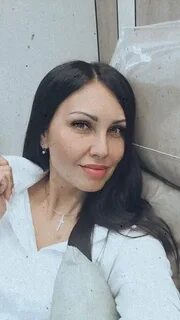

In [9]:
get_image(data.sample(1)['image'].tolist()[0])

В данных есть выбросы — записи, не относящихся к туристическим или историческим объектам. Для очистки данных можно, например, использовать алгоритм TF-IDF: создаем корпус текстов из описаний, применяем TF-IDF, извлекаем наиболее редко или часто встречающиеся слова. Они могут указывать на мусорные данные, такие как мемы, баннеры или личные фото людей. После выделения подозрительных паттернов, можно провести ручную проверку и фильтрацию данных.

Для дальнейшего тестирования и получения чистых сэмплов, рекомендуется взять не менее 100 чистых образцов со стратификацией по городу и названию места. Это можно сделать, выбрав случайным образом несколько образцов из каждой категории (город + название места), чтобы обеспечить равномерное представительство и разнообразие данных.

**!! Важно:** Помните, что чистые сэмплы одного и того же места выдадут примерно одинаковое описание. Есть несколько стратегий, как повысить разнообразие ответов:

- выбор одного самого лучшего:
  - самое длинное описание
  - смое подходящие по мнению LLM
- конкатенация описаний (но важно не сконкатенировать слишком много)

Изображения можно отдать в мета-данные.

In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity


# Очистим данные на основании типичности описания en_txt
texts = data["en_txt"].fillna("").astype(str)

vectorizer = TfidfVectorizer(stop_words="english")
X = vectorizer.fit_transform(texts)

# Разделяем дубли и одиночные записи
groups = data.groupby("WikiData", dropna=False).indices

keep = []
single_indices = []

for indices in groups.values():
    if len(indices) == 1:
        single_indices.append(indices[0])
        continue

    # Оставляем наиболее типичное описание среди дублирующих записей
    similarity = cosine_similarity(X[indices])
    scores = (similarity.sum(axis=1) - 1) / (len(indices) - 1)

    keep.append(indices[np.argmax(scores)])

# Отфильтруем необычные описания в одиночных записях (если бы они были)
if len(single_indices) > 0:
    X_single = X[single_indices]

    scores = np.asarray(X_single.sum(axis=1)).ravel()
    counts = X_single.getnnz(axis=1)
    scores = scores / np.maximum(counts, 1)

    threshold = np.quantile(scores, 0.80)
    keep.extend(np.array(single_indices)[scores <= threshold])

data_clean = data.iloc[keep].reset_index(drop=True)

print(f"До: {len(data)}")
print(f"После: {len(data_clean)}")

До: 14634
После: 297


Здесь предлагаем вам построить RAG с использованием моделей, которые не были представлены на семинаре (включая другие векторные базы данных). Можно воспользоваться материалами по этой ссылке: [data_connection/vectorstores](https://python.langchain.com/v0.1/docs/modules/data_connection/vectorstores/).

!Важно, не забудьте отранжировать чанки текстов с помощью `ragatouille`. На практике порядок текстов в промпте влияет на точность ответа.

!!!
`ragatouille` устарел, разработчики сами предлагают вместо него использовать `pylate`.

In [10]:
# Для нашей даты не вижу смысла разбивать на чанки тк описания и так короткие
print(f"Максимальная длина описания: {data_clean["en_txt"].str.len().max()}")

Максимальная длина описания: 77


In [11]:
import chromadb
from sentence_transformers import SentenceTransformer


# Создаём векторную базу
embedding_model = SentenceTransformer("BAAI/bge-m3")

texts = [
    (
        f"Name: {row["Name"]}\n"
        f"City: {row["City"]}\n"
        f"WikiData description: {row["description"]}\n"
        f"Image description: {row["en_txt"]}"
    )
    for _, row in data_clean.iterrows()
]

embeddings = embedding_model.encode(
    texts,
    normalize_embeddings=True,
    show_progress_bar=True
)

client = chromadb.Client()
collection = client.get_or_create_collection(
    name="tourist_rag",
    metadata={"hnsw:space": "cosine"}
)

collection.upsert(
    ids=[str(i) for i in range(len(texts))],
    documents=texts,
    embeddings=embeddings.tolist(),
    metadatas=[
        {
            "WikiData": str(row["WikiData"]),
            "Lon": str(row["Lon"]),
            "Lat": str(row["Lat"]),
            "Image": str(row["image"])
        }
        for _, row in data_clean.iterrows()
    ]
)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/123 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/15.8k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/54.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/687 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 2.27GB            

... (8 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/964 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/191 [00:00<?, ?B/s]

Batches:   0%|          | 0/10 [00:00<?, ?it/s]

In [12]:
from pylate import models, rank


# Создаем извлечение с реранкингом
reranker = models.ColBERT(
    model_name_or_path="lightonai/colbertv2.0"
)

def retrieve(query, top_k=10, rerank_k=5):
    query_embedding = embedding_model.encode(
        query, normalize_embeddings=True
    ).tolist()

    results = collection.query(
        query_embeddings=[query_embedding],
        n_results=top_k
    )

    documents = results["documents"][0]
    ids = results["ids"][0]

    if not documents:
        return []

    q_emb = reranker.encode([query], is_query=True)
    d_emb = reranker.encode([documents], is_query=False)

    ranked = rank.rerank(
        documents_ids=[list(range(len(documents)))],
        queries_embeddings=q_emb,
        documents_embeddings=d_emb
    )[0]

    return [
        {
            "id": int(ids[int(item["id"])]),
            "content": documents[int(item["id"])],
            "score": item["score"]
        }
        for item in ranked[:rerank_k]
    ]

modules.json:   0%|          | 0.00/216 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/669 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/4.67k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/663 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

... (2 outputs left out)

tokenizer_config.json:   0%|          | 0.00/1.56k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/712k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/582 [00:00<?, ?B/s]

In [13]:
# Тестим

query = "What historical monuments can I visit?"
results = retrieve(query, top_k=10, rerank_k=5)

retrieved_docs = []

for doc in results:
    row = dict(
        line.split(": ", 1)
        for line in doc["content"].splitlines()
        if ": " in line
    )
    row["Score"] = round(float(doc["score"]), 3)
    retrieved_docs.append(row)

pd.DataFrame(retrieved_docs)[["Score", "Name", "City", "WikiData description", "Image description"]]

,Score,Name,City,WikiData description,Image description
0,12.444,Обелиск Минину и Пожарскому,Нижний Новгород,"памятник в Нижнем Новгороде, Россия",a view of a monument in a park with a clock on it
1,11.241,Воинское мемориальное кладбище,Ярославль,Воинское мемориальное кладбище (Ярославль),there are two soldiers standing next to a monu...
2,10.881,Памятник жертвам белогвардейского мятежа,Ярославль,Памятник жертвам белогвардейского мятежа,arafed monument in the park with a clock on it
3,10.853,Памятник жертвам и мученикам революции 1905 года,Нижний Новгород,Памятник героям и жертвам революции 1905 года,there is a monument in the middle of a park wi...
4,6.681,Золотые ворота,Владимир,памятник XII века во Владимире,arafed view of a white building with a golden ...


Выполните визуализацию эмбеддингов при помощи метода главных компонент (PCA) и Uniform Manifold Approximation and Projection (UMAP). Пожалуйста, выполните PCA независимо от pacmap.

In [14]:
from sklearn.decomposition import PCA
from umap import UMAP


X = np.asarray(embeddings)

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X)

umap_model = UMAP(
    n_components=2,
    n_neighbors=15,
    min_dist=0.1,
    metric="cosine",
    random_state=42
)
X_umap = umap_model.fit_transform(X)

print(f"PCA explained variance: {pca.explained_variance_ratio_.sum():.2%}")

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


PCA explained variance: 17.14%


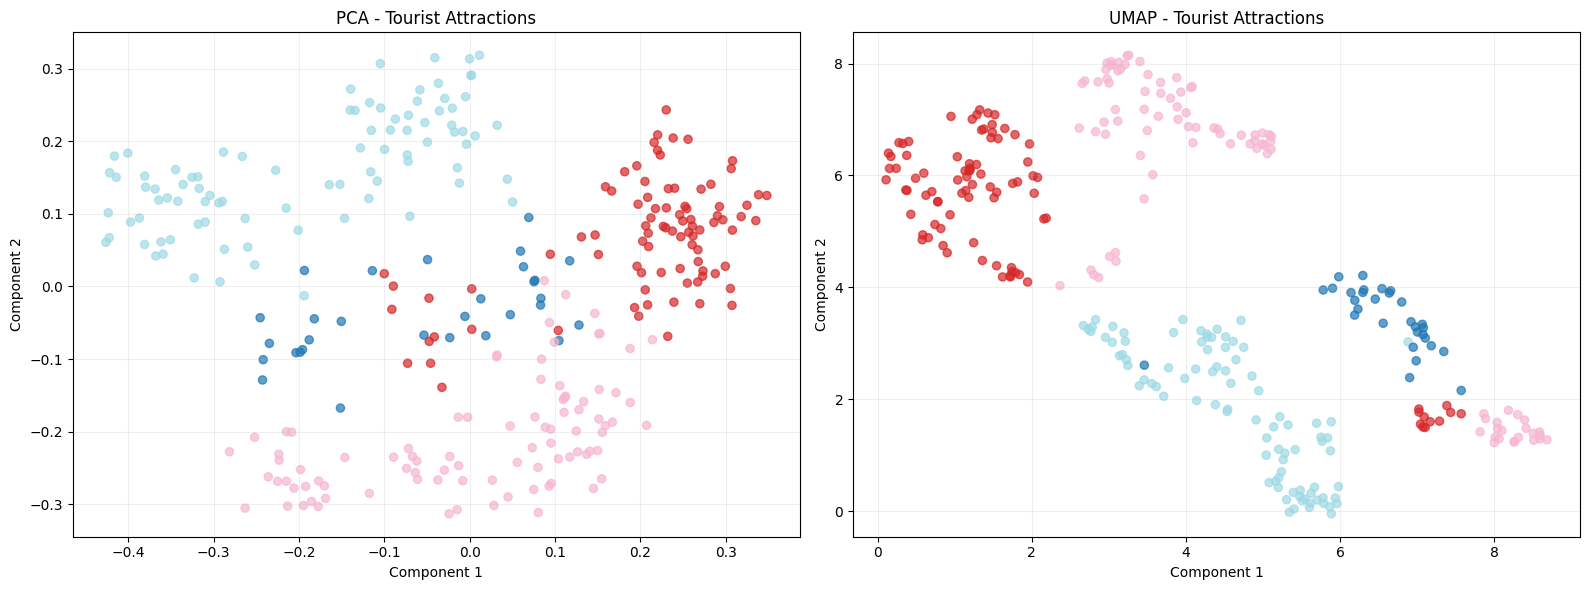

In [15]:
cities = data_clean["City"].reset_index(drop=True)
city_codes = pd.Categorical(cities).codes

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, (title, coords) in zip(
    axes, [("PCA", X_pca), ("UMAP", X_umap)]
):
    ax.scatter(
        coords[:, 0],
        coords[:, 1],
        c=city_codes,
        cmap="tab20",
        s=35,
        alpha=0.7
    )

    ax.set_title(f"{title} - Tourist Attractions")
    ax.set_xlabel("Component 1")
    ax.set_ylabel("Component 2")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

# RAGAS (3 балла)

RAGAS - это система, созданная для автоматической оценки эффективности модели RAG. Она представляет собой комплексный инструмент, способный оценить как качество извлечения информации, так и качество созданного текста. Это достигается благодаря использованию различных метрик, которые анализируют разные аспекты ответов, сгенерированных языковой моделью.



## Метрики оценки в RAGAS

### Faithfulness
Оценивает, насколько ответы языковой модели верно передают информацию, содержащуюся в источниках данных. Это критически важно, чтобы гарантировать, что модель не искажает или не меняет информацию при её интерпретации.

---

$
Faithfulness = \frac{\text{|Number of claims that can be inferred from given context|}}{\text{|Total number of claims in the generated answer|}}
$

### Answer Relevancy
Демонстрирует, насколько ответы соответствуют заданным вопросам. Это важный аспект, так как даже правильный ответ с технической точки зрения может быть ненужным, если он не отвечает на конкретный вопрос пользователя.

---

$\text{answer relevancy} = \frac{1}{N} \sum_{i=1}^{N} cos(E_{g_i}, E_o)$

$\text{answer relevancy} = \frac{1}{N} \sum_{i=1}^{N} \frac{E_{g_i} \cdot E_o}{\|E_{g_i}\|\|E_o\|}$

Где:

* $E_{g_i}$ - это эмбеддинг сгенерированного ответа $i$

* $E_o$ - это эмбеддинг исходного вопроса.

* $N$ - это количество сгенерированных вопросов, которое по умолчанию равно 3.

### Context Recall и Context Precision
Эти метрики измеряют эффективность модели в учете контекста вопроса для формирования ответа. "Context Recall" оценивает количество использованной информации из контекста в ответе, в то время как "Context Precision" оценивает точность и релевантность использования контекстной информации.

---

* $ \text{context recall} = \frac{\text{|GT sentences that can be attributed to context|}}{\text{|Number of sentences in GT|}} $
* $Context Precision@k = \frac{\sum \text{precision@k}}{\text{total number of relevant items in the top K results}}$
  * $Precision@k = \frac{\text {true positives@k}}{\text{(true positives@k + false positives@k)}}$

### Answer Semantic Similarity
Оценивает степень семантической близости между ответом модели и эталонным ответом. Это позволяет определить, насколько естественно и точно модель способна воссоздавать человеческий язык.

### Answer Correctness
Оценка корректности ответа. Это последний шаг в проверке, чтобы убедиться, предоставляет ли модель точную и достоверную информацию в своем ответе.

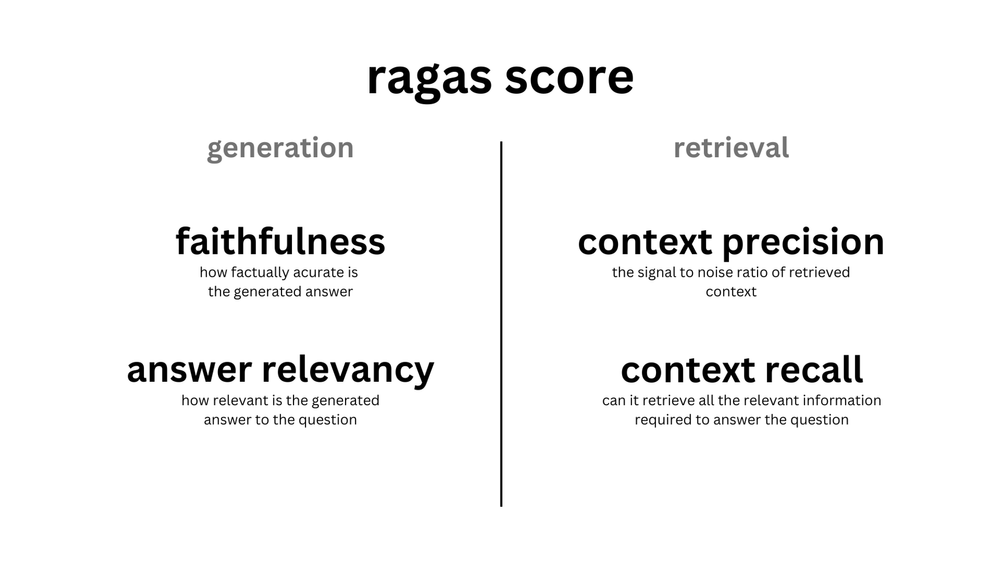

В этом задании вам нужно реализовать метрику answer_relevancy в коде. Опционально за допбаллы можно реализовать другие метрики.

Для этого датасет нужно привести к виду, в котором будут следующие поля:

### 1. question
- Смысл: Эта колонка содержит вопросы, на которые нужно найти ответы. В контексте задач QA, это основная информация, которую модель должна обработать для генерации ответа.
- Пример: "Каковы преимущества RAG?"

### 2. ground_truths
- Смысл: В этой колонке находятся правильные ответы на соответствующие вопросы. Это может использоваться для оценки производительности модели, так как позволяет сравнить сгенерированные ответы с эталонными.
- Пример: "RAG улучшает качество генерации, используя внешние источники информации."

### 3. answer
- Смысл: Эта колонка содержит ответы, которые генерирует модель на основе заданных вопросов. Это может быть результат работы модели, которую вы тестируете или обучаете.
- Пример: "RAG позволяет моделям извлекать информацию из внешних источников, что улучшает их способность отвечать на сложные вопросы."

### 4. contexts
- Смысл: Эта колонка предоставляет контекст или дополнительную информацию, которая может быть полезна для понимания вопроса или для формирования ответа. Это может быть текст, из которого был извлечен ответ, или другие релевантные документы.
- Пример: "RAG (Retrieval-Augmented Generation) — это метод, который использует внешние базы данных для получения информации при генерации текста."

HINT: Поле question можно тоже сгенерировать. Например, можно попросить модель задать вопрос по описанию изображения.

HINT: Для answer_relevancy нужны не все поля

HINT: Инференс такого эксперимента может быть долгим. План минимум: возьмите 100 случайных сэмплов.

In [16]:
# import re
# import json
# import numpy as np
# import pandas as pd
# from pathlib import Path
# from tqdm.auto import tqdm
from transformers import pipeline
# from pylate import rank

In [17]:
llm = pipeline(
    "text-generation",
    model="Qwen/Qwen2.5-0.5B-Instruct",
    device_map="auto",
    dtype="auto"
)

def generate(prompt, max_new_tokens=120, do_sample=False):
    messages = [
        {"role": "user", "content": prompt}
    ]

    kwargs = {
        "max_new_tokens": max_new_tokens,
        "do_sample": do_sample,
    }

    if do_sample:
        kwargs["temperature"] = 0.8
        kwargs["top_p"] = 0.9

    result = llm(messages, **kwargs)

    return result[0]["generated_text"][-1]["content"].strip()

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

In [18]:
def generate_question(wiki_description, image_description):
    prompt = f"""
You are a tourist looking for interesting places to visit.

Create ONE natural tourist search question based on:

WikiData description: {wiki_description}
Image description: {image_description}

Rules:
- Use information from either or both descriptions.
- Do not invent details.
- Do not mention the place name.
- Make the question natural and specific.
- Return only the question.
- Write in English.
"""
    return generate(prompt, max_new_tokens=80)

In [19]:
def generate_rag_answer(question, documents):
    contexts = [doc["content"] for doc in documents]

    prompt = f"""
You are a helpful tourist guide.

Answer the question using only the provided context.
Recommend relevant places by name and city.
Do not invent information.
If no relevant place is found, say so.
Keep the answer short.

Context:
{chr(10).join(contexts)}

Question: {question}

Answer:
"""

    answer = generate(prompt, max_new_tokens=150)

    return answer, contexts

In [20]:
def data_preprocess(data_clean, n=100):
    sample = data_clean[
        data_clean["en_txt"].fillna("").str.strip().ne("")
    ].sample(
        n=min(n, data_clean["en_txt"].fillna("").str.strip().ne("").sum()),
        random_state=42
    )

    rows = []

    for source_id, row in tqdm(
        sample.iterrows(),
        total=len(sample),
        desc="Generating QA dataset"
    ):
        # Генерируем вопрос из двух описаний
        question = generate_question(
            row["description"],
            row["en_txt"]
        )

        # Поиск + reranking
        documents = retrieve(
            question,
            top_k=10,
            rerank_k=5
        )

        # Ответ LLM
        answer, contexts = generate_rag_answer(
            question,
            documents
        )

        rows.append({
            "question": question,
            "ground_truths": [
                f"{row['Name']} in {row['City']}. "
                f"{row['description']}"
            ],
            "answer": answer,
            "contexts": contexts,
            "source_id": int(data_clean.index.get_loc(source_id)),
            "retrieved_ids": [d["id"] for d in documents],
            "WikiData": row["WikiData"]
        })

    return pd.DataFrame(rows)

In [21]:
# Протестируем на 5 записях
eval_df = data_preprocess(data_clean, n=5)

eval_df[["question", "answer", "ground_truths"]]

Generating QA dataset:   0%|          | 0/5 [00:00<?, ?it/s]

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
Passing `generation_config` together with generation-related arguments=({'max_new_tokens', 'do_sample'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
Both `max_new_tokens` (=80) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=150) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=80) and `max_length`(=20) seem to have been set. `max_new_tokens`

,question,answer,ground_truths
0,What unique architectural style does the Nikol...,Nikol-Skovorodsky Monastery exhibits the tradi...,[Николо-Сковородский монастырь in Ярославль. Н...
1,What unique architectural style does the blue ...,The unique architectural style showcased by th...,[Храм в честь Вознесения Господня in Екатеринб...
2,What unique architectural style does this chur...,Arabidene White Church,[Церковь Рождества Иоана Предтечи in Нижний Но...
3,What unique architectural style does this smal...,Wooden house with a metal roof reflects the ar...,[Музей «Литературная жизнь Урала XIX века» in ...
4,What unique hotel located near the clock tower...,Дом Э. Ф. Филитц,"[Здание бывшей гостиницы ""Мадрид"" in Екатеринб..."


In [ ]:
eval_df = data_preprocess(data_clean, n=100)

eval_df.to_json(
    "rag_eval_dataset.json",
    orient="records",
    force_ascii=False,
    indent=2
)

In [ ]:
# Реализуем Answer Relevancy

def answer_relevancy(question, answer, n=3):
    if not answer or not answer.strip():
        return 0.0

    generated_questions = []

    for _ in range(n):
        prompt = f"""
Generate ONE natural question that could be answered
by the following text.

Answer:
{answer}

Return only the question.
"""

        generated_questions.append(
            generate(
                prompt,
                max_new_tokens=80,
                do_sample=True
            )
        )

    vectors = embedding_model.encode(
        [question] + generated_questions,
        normalize_embeddings=True
    )

    similarities = vectors[1:] @ vectors[0]

    return float(np.mean(similarities))

# Протестируйте ваш RAG (3 балла)

In [ ]:
eval_df["answer_relevancy"] = [
    answer_relevancy(q, a)
    for q, a in tqdm(
        zip(eval_df["question"], eval_df["answer"]),
        total=len(eval_df),
        desc="Answer Relevancy"
    )
]

print(f"Answer Relevancy: {eval_df['answer_relevancy'].mean():.3f}")

# Дополнительная часть (+3 балла)

Реализуйте одну из метрик retrieval-части на выбор.

Для того, чтобы понять model as a judge подход из RAGAS, советуем посетить [этот кукбук](https://huggingface.co/learn/cookbook/en/rag_evaluation)

In [1]:
# Реализуем Recall@5

def recall_at_k(source_id, retrieved_ids, k=5):
    return int(source_id in retrieved_ids[:k])

eval_df["recall@5"] = eval_df.apply(
    lambda row: recall_at_k(
        row["source_id"],
        row["retrieved_ids"]
    ),
    axis=1
)

print(f"Recall@5: {eval_df['recall@5'].mean():.3f}")

In [1]:
display(
    eval_df[[
        "question",
        "answer",
        "answer_relevancy",
        "recall@5"
    ]].round(3)
)

eval_df.to_json(
    "rag_eval_results.json",
    orient="records",
    force_ascii=False,
    indent=2
)